# 04 · Model evaluation & explainability

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.max_columns', 40)

In [2]:
from src.config import MODELS_DIR
reg = json.loads((MODELS_DIR/'registry.json').read_text())
d = MODELS_DIR/reg['diabetes_risk']['path']
m = json.loads((d/'metrics.json').read_text())

In [3]:
rows = {}
for k, v in m['models'].items():
    t = v['test']; a = t['at_threshold']
    rows[v['display_name']] = {'ROC-AUC': t['roc_auc'], 'PR-AUC': t['pr_auc'], 'Brier': t['brier'], 'threshold': a['threshold'],
        'recall': a['recall'], 'precision': a['precision'], 'specificity': a['specificity'], 'F1': a['f1'], 'F2': a['f2'],
        'FN': a['confusion_matrix']['fn'], 'FP': a['confusion_matrix']['fp'], 'accuracy@0.5': t['at_0_5']['accuracy']}
pd.DataFrame(rows).T.sort_values('PR-AUC', ascending=False).round(4)

,ROC-AUC,PR-AUC,Brier,threshold,recall,precision,specificity,F1,F2,FN,FP,accuracy@0.5
XGBoost,0.8270,0.4165,0.0975,0.1209,0.8550,0.2775,0.6396,0.4190,0.6037,1025.0,15737.0,0.8653
Gradient Boosting (HistGradientBoosting),0.8265,0.4145,0.0975,0.1261,0.8366,0.2869,0.6634,0.4273,0.6049,1155.0,14698.0,0.8658
Random Forest,0.8220,0.4060,0.0983,0.1261,0.8362,0.2821,0.6555,0.4219,0.6004,1158.0,15042.0,0.8651
"Support Vector Machine (linear, calibrated)",0.8202,0.3933,0.0990,0.1266,0.8336,0.2831,0.6582,0.4226,0.6002,1176.0,14926.0,0.8633
Logistic Regression,0.8201,0.3915,0.0990,0.1297,0.8315,0.2860,0.6639,0.4256,0.6019,1191.0,14675.0,0.8629
K-Nearest Neighbors,0.8134,0.3914,0.0997,0.1259,0.8414,0.2681,0.6281,0.4066,0.5893,1121.0,16241.0,0.8642
Decision Tree,0.8145,0.3904,0.0994,0.1322,0.8380,0.2751,0.6425,0.4142,0.5946,1145.0,15611.0,0.8639


Accuracy at 0.5 looks high for every model only because 86% of respondents are negative. A model that always predicts 'no diabetes' would score 0.86. PR-AUC, recall and the FN/FP counts are the informative metrics here.

In [4]:
sel = m['selected']
print(json.dumps(sel['bootstrap_test'], indent=2)); print(json.dumps(sel['duplicate_sensitivity'], indent=2))

{
  "roc_auc_95ci": [
    0.8223,
    0.8318
  ],
  "pr_auc_95ci": [
    0.405,
    0.4292
  ],
  "n_bootstrap": 200
}
{
  "test_rows_with_feature_vector_unseen_in_train": 44649,
  "unseen_roc_auc": 0.8184,
  "unseen_pr_auc": 0.4233
}


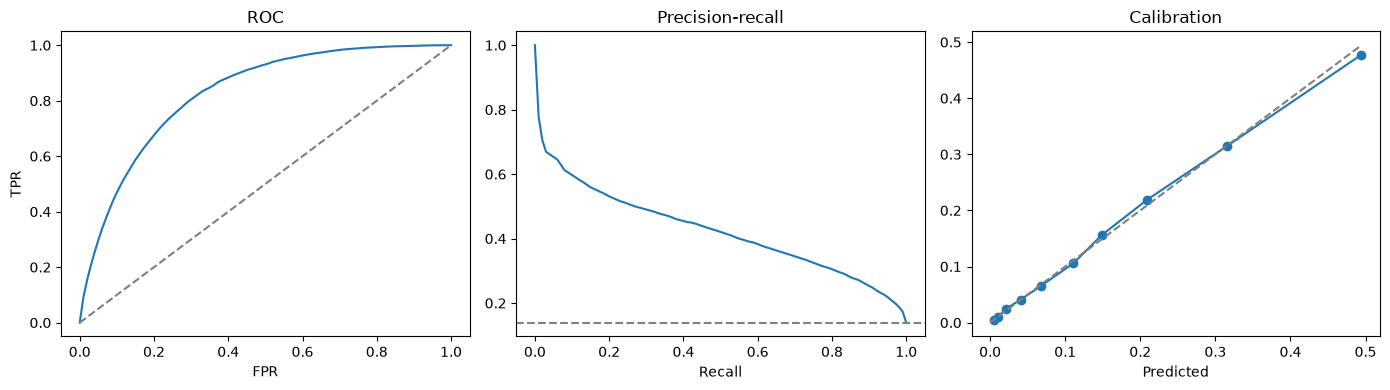

In [5]:
c = sel['curves_test']
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
r = pd.DataFrame(c['roc']); ax[0].plot(r.fpr, r.tpr); ax[0].plot([0,1],[0,1],'--',c='grey'); ax[0].set(title='ROC', xlabel='FPR', ylabel='TPR')
p = pd.DataFrame(c['pr']); ax[1].plot(p.recall, p.precision); ax[1].axhline(m['splits']['test']['positive_rate'], ls='--', c='grey'); ax[1].set(title='Precision-recall', xlabel='Recall')
k = pd.DataFrame(c['calibration']); ax[2].plot(k.mean_predicted, k.observed_rate, 'o-'); ax[2].plot([0,k.mean_predicted.max()],[0,k.mean_predicted.max()],'--',c='grey'); ax[2].set(title='Calibration', xlabel='Predicted')
plt.tight_layout()

In [6]:
pd.DataFrame(sel['threshold_table_val']).drop(columns='confusion_matrix').round(3)

,threshold,accuracy,precision,recall,specificity,f1,f2,false_negative_rate,false_positive_rate
0,0.05,0.526,0.221,0.950,0.457,0.358,0.572,0.050,0.543
1,0.10,0.652,0.269,0.873,0.616,0.412,0.603,0.127,0.384
2,0.15,0.726,0.310,0.787,0.716,0.445,0.602,0.213,0.284
3,0.20,0.799,0.372,0.643,0.824,0.471,0.561,0.357,0.176
4,0.25,0.821,0.401,0.575,0.861,0.473,0.529,0.425,0.139
5,0.30,0.841,0.436,0.484,0.899,0.459,0.474,0.516,0.101
6,0.35,0.856,0.478,0.379,0.933,0.423,0.396,0.621,0.067
7,0.40,0.859,0.493,0.342,0.943,0.404,0.364,0.658,0.057
8,0.45,0.865,0.533,0.244,0.965,0.335,0.274,0.756,0.035
9,0.50,0.867,0.599,0.142,0.985,0.230,0.168,0.858,0.015


## Explainability (SHAP)
Global importance on 2,000 held-out test respondents. SHAP values describe the model's behaviour. They are **not causal effects**.

In [7]:
from src.evaluation import explain_global
s = explain_global.run()
pd.DataFrame([{k: f[k] for k in ('label','mean_abs_shap','mean_shap')} for f in s['features']])

C:\Users\archi\Desktop\Healthcare\medicore-ai\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,label,mean_abs_shap,mean_shap
0,Self-rated general health (1=excellent…5=poor),0.68565,-0.30924
1,Age group (1=18–24 … 13=80+),0.41316,-0.14568
2,Body mass index,0.35168,-0.09783
3,Cardiometabolic conditions (engineered),0.34489,-0.14040
4,High blood pressure,0.22788,-0.06357
5,Income band (1–8),0.13885,-0.03095
6,Sex (1=male),0.12584,-0.01295
7,High cholesterol,0.09587,-0.02131
8,BMI category (engineered),0.07552,-0.02138
9,Cholesterol check (5 yrs),0.06902,-0.02653


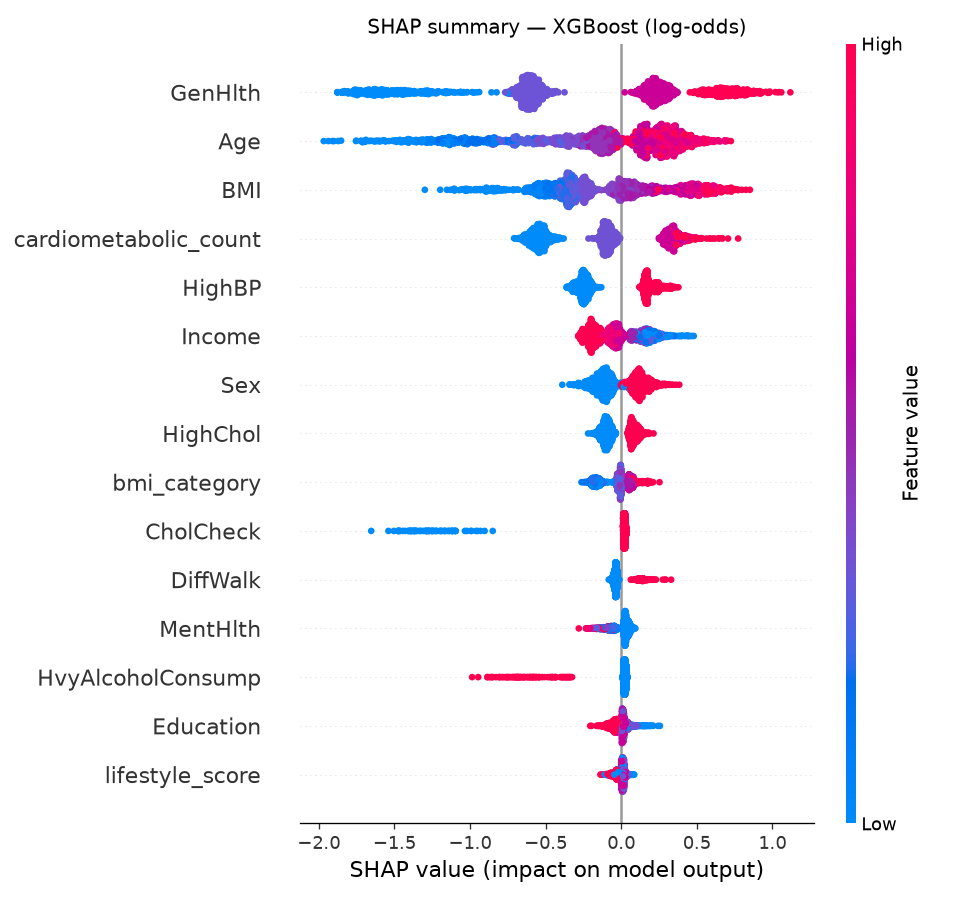

In [8]:
display(Image(filename=str(ROOT/'docs'/'figures'/'shap_summary.png')))

## Segmentation

In [9]:
from src.segmentation import cluster
seg = cluster.run()
pd.DataFrame(seg['selection'])

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,208917.1,0.3308,1.6325,8770.8
1,3,185509.5,0.1615,1.9327,6831.1
2,4,169327.7,0.1688,1.8506,5944.7
3,5,158367.7,0.1315,1.8402,5285.8
4,6,148215.1,0.1601,1.8205,4929.1
5,7,140747.8,0.1397,1.7691,4590.6
6,8,133895.3,0.1395,1.7482,4355.3


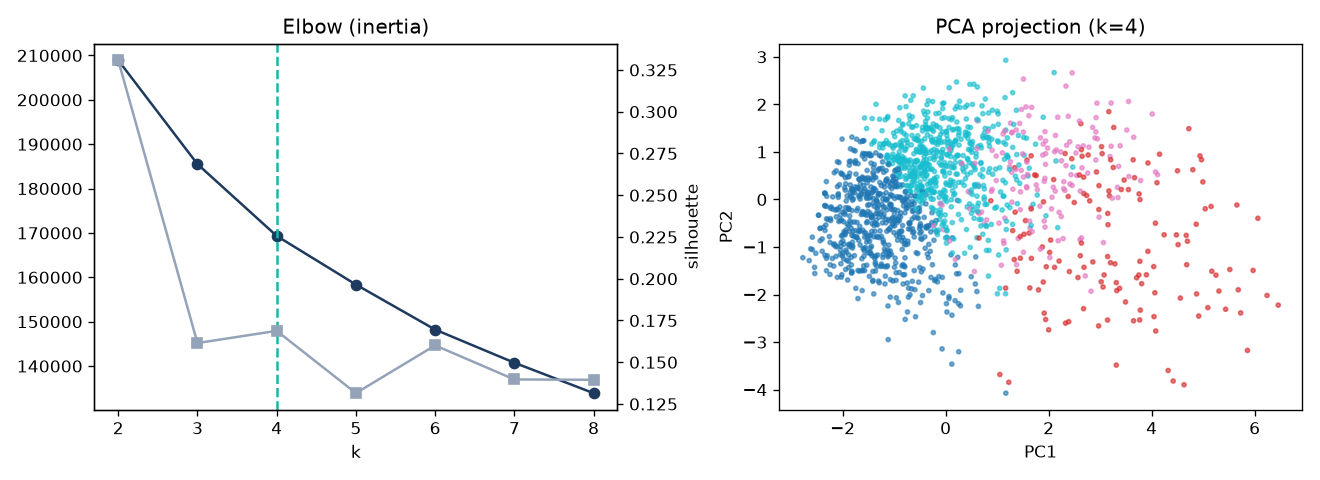

In [10]:
display(Image(filename=str(ROOT/'docs'/'figures'/'segmentation.png')))

In [11]:
pd.DataFrame([{**{'segment': s['name'], 'share': s['share'], 'diabetes_rate': s['observed_diabetes_rate']}, **s['feature_means']} for s in seg['segments']])

,segment,share,diabetes_rate,BMI,GenHlth,MentHlth,PhysHlth,Age,Income,cardiometabolic_count,lifestyle_score,DiffWalk
0,Segment A,0.4266,0.0267,26.663,1.904,2.094,1.164,5.993,6.936,0.285,4.082,0.003
1,Segment B,0.1109,0.3027,30.882,4.081,14.006,24.697,8.569,4.262,1.597,3.076,0.650
2,Segment C,0.0946,0.2915,31.180,3.151,2.091,4.277,9.912,4.880,1.549,3.374,1.000
3,Segment D,0.3679,0.1816,28.891,2.581,1.475,1.654,9.773,5.864,1.475,3.543,0.000
